In [59]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
df=pd.read_csv("Social_Network_Ads.csv")

In [61]:
df.sample(10)

,Age,EstimatedSalary,Purchased
351,37,75000,0
228,40,72000,0
169,29,47000,0
271,59,76000,1
303,37,79000,1
85,31,118000,1
74,32,18000,0
127,26,32000,0
279,50,36000,1
246,35,50000,0


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              400 non-null    int64
 1   EstimatedSalary  400 non-null    int64
 2   Purchased        400 non-null    int64
dtypes: int64(3)
memory usage: 9.5 KB


In [63]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [64]:
df.isnull().sum()

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

<Axes: xlabel='Age', ylabel='Count'>

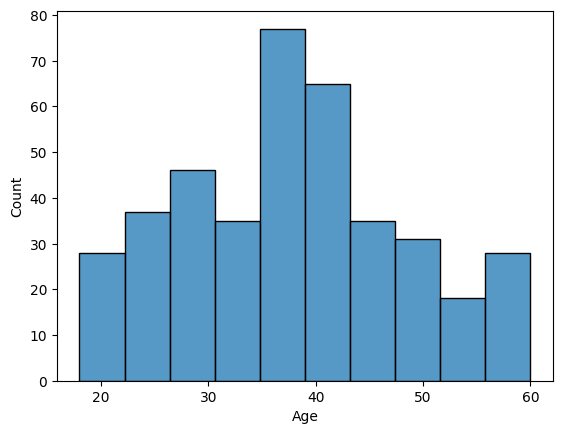

In [65]:
sns.histplot(x=df["Age"])

<Axes: xlabel='Age'>

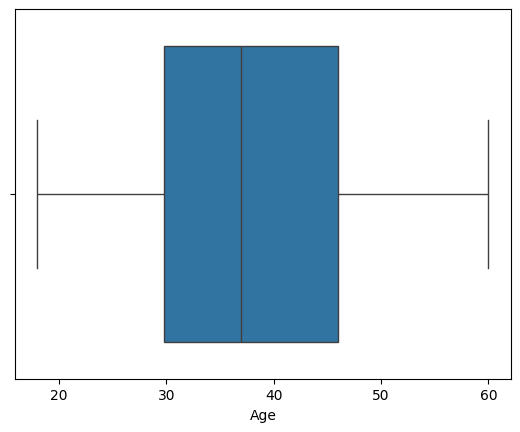

In [66]:
sns.boxplot(x=df["Age"])

<Axes: xlabel='EstimatedSalary'>

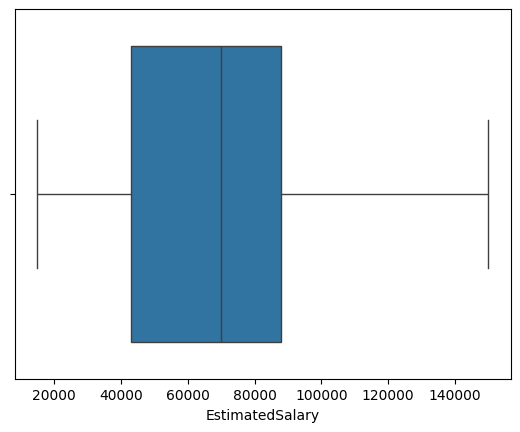

In [67]:
sns.boxplot(x=df["EstimatedSalary"])

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
x_train,x_test,y_train,y_test=train_test_split(
    df.drop("Purchased",axis=1),
    df["Purchased"],
    test_size=0.3,
    random_state=48
)

In [70]:
x_train.shape,x_test.shape

((280, 2), (120, 2))

In [71]:
from sklearn.preprocessing import StandardScaler

In [72]:
scaler=StandardScaler()

In [73]:
scaler.fit(x_train)

StandardScaler()

In [74]:
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [75]:
x_test_scaled

array([[-1.09458928, -1.59476003],
       [ 1.63935872,  1.81140029],
       [-1.75450776, -1.26895339],
       [ 1.73363279,  1.04131187],
       [ 1.73363279, -0.26191469],
       [-1.09458928,  1.45597487],
       [-0.81176707,  0.41931738],
       [ 2.016455  ,  0.5674113 ],
       [ 0.41379582,  0.62664887],
       [-1.09458928,  0.33046102],
       [-0.52894487,  1.42635608],
       [ 1.07371431,  2.13720693],
       [-0.24612266,  0.24160466],
       [ 0.88516617, -0.52848376],
       [ 0.03669955, -0.52848376],
       [-1.18886335,  0.53779252],
       [-0.05757452, -0.41000862],
       [ 0.03669955,  0.06389195],
       [-0.717493  ,  1.39673729],
       [ 1.07371431, -1.20971582],
       [-1.00031521,  0.62664887],
       [ 0.97944024,  1.84101908],
       [-0.24612266,  2.31491964],
       [-0.4346708 , -1.12085946],
       [-0.717493  , -0.20267712],
       [-0.24612266,  0.12312952],
       [-0.05757452,  2.22606329],
       [-0.24612266,  0.06389195],
       [-0.62321893,

In [76]:
scaler.mean_

array([3.76107143e+01, 6.88428571e+04])

In [77]:
x_train_scaled=pd.DataFrame(x_train_scaled,columns=x_train.columns,index=x_train.index)
x_test_scaled=pd.DataFrame(x_test_scaled,columns=x_test.columns,index=x_test.index)

In [78]:
x_train_scaled.head()

,Age,EstimatedSalary
132,-0.717493,0.537793
372,0.130974,0.123130
56,-1.377411,-0.617340
141,-1.848782,-0.024964
333,0.225248,-0.113821


In [79]:
np.round(x_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,-0.0,-0.0
std,1.0,1.0
min,-1.8,-1.6
25%,-0.8,-0.8
50%,-0.1,-0.1
75%,0.8,0.5
max,2.1,2.4


## Effects of Scaling

Text(0.5, 1.0, 'After Scaling')

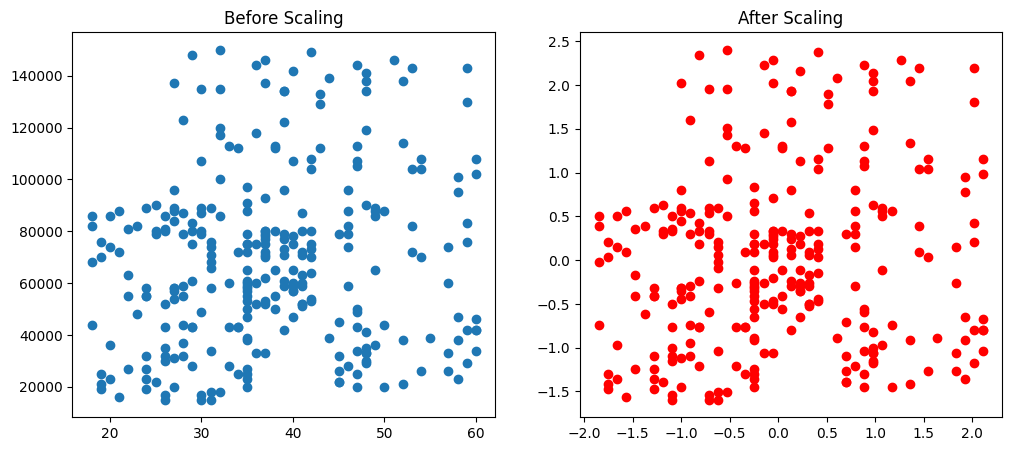

In [80]:
fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
ax1.scatter(x_train["Age"],x_train["EstimatedSalary"])
ax1.set_title("Before Scaling")
ax2.scatter(x_train_scaled["Age"], x_train_scaled["EstimatedSalary"],color="red")
ax2.set_title("After Scaling")

### This above scatter plot shows how before after standardization the graph looks only changes is range and mean and standard deviation

<Axes: title={'center': 'After Scaling'}, xlabel='Age', ylabel='Density'>

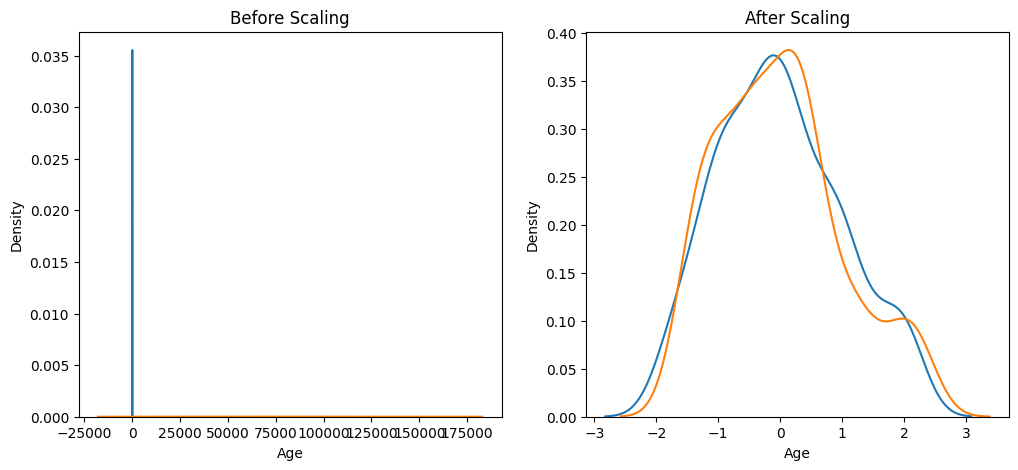

In [81]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
#before scaling
ax1.set_title("Before Scaling")
sns.kdeplot(x_train["Age"],ax=ax1)
sns.kdeplot(x_train["EstimatedSalary"],ax=ax1)
#after scaling
ax2.set_title("After Scaling")
sns.kdeplot(x_train_scaled["Age"],ax=ax2)
sns.kdeplot(x_train_scaled["EstimatedSalary"],ax=ax2)


### Above kde shows how range differ before after like after standardization the range become closer to each other which helps in ml algo function faster

## Comparision of distribution

<Axes: title={'center': 'Age distribution After Scaling'}, xlabel='Age', ylabel='Density'>

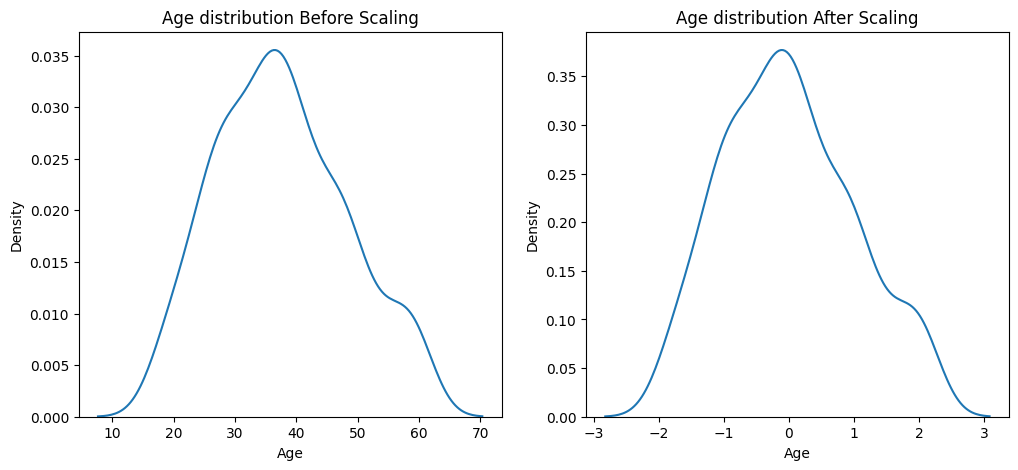

In [82]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
#before scaling
ax1.set_title("Age distribution Before Scaling")
sns.kdeplot(x_train["Age"],ax=ax1)

#after scaling
ax2.set_title("Age distribution After Scaling")
sns.kdeplot(x_train_scaled["Age"],ax=ax2)


<Axes: title={'center': 'EstimatedSalary distribution After Scaling'}, xlabel='EstimatedSalary', ylabel='Density'>

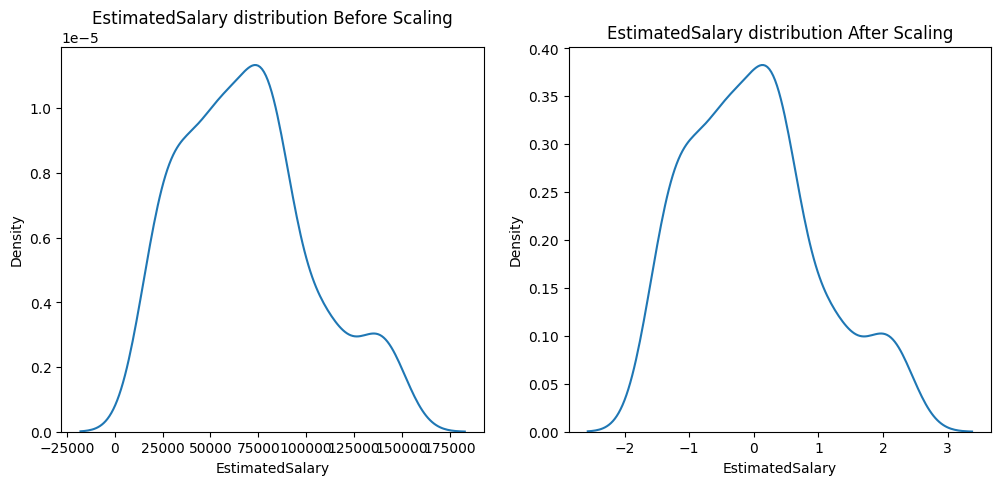

In [83]:
fig,(ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))
#before scaling
ax1.set_title("EstimatedSalary distribution Before Scaling")
sns.kdeplot(x_train["EstimatedSalary"],ax=ax1)
#after scaling
ax2.set_title("EstimatedSalary distribution After Scaling")
sns.kdeplot(x_train_scaled["EstimatedSalary"],ax=ax2)

### As we can see above graph there is no change in distribution in before-after standardization only changes in range/scale

## Why is Feature Scaling is important

In [84]:
from sklearn.linear_model import LogisticRegression

In [85]:
lr=LogisticRegression()
lr_scaled=LogisticRegression()

In [86]:
lr.fit(x_train,y_train)
lr_scaled.fit(x_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [87]:
y_pred=lr.predict(x_test)
y_pred_scaled=lr_scaled.predict(x_test_scaled)

In [88]:
from sklearn.metrics import accuracy_score

In [89]:
print(f"Actual:{accuracy_score(y_test,y_pred)}\nScaled:{accuracy_score(y_test,y_pred_scaled)}")

Actual:0.8666666666666667
Scaled:0.8666666666666667


In [90]:
from sklearn.tree import DecisionTreeClassifier

In [91]:
dt=DecisionTreeClassifier()
dt_scaled=DecisionTreeClassifier()

In [92]:
dt.fit(x_train,y_train)
dt_scaled.fit(x_train_scaled,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [93]:
y_pred=dt.predict(x_test)
y_pred_scaled=dt_scaled.predict(x_test_scaled)

In [95]:
print(f"Actual:{accuracy_score(y_test,y_pred)}\nScaled:{accuracy_score(y_test,y_pred_scaled)}")

Actual:0.8666666666666667
Scaled:0.8666666666666667


In [96]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


## Effects of outlier(copied from campusx code below one only coz to tired today but understood every thing)

In [99]:
df = pd.concat([
    df,
    pd.DataFrame({
        'Age': [5, 90, 95],
        'EstimatedSalary': [1000, 250000, 350000],
        'Purchased': [0, 1, 1]
    })
], ignore_index=True)

In [100]:
df.sample(10)

,Age,EstimatedSalary,Purchased
49,31,89000,0
330,38,51000,0
214,47,43000,0
253,37,146000,1
268,47,144000,1
276,38,71000,0
35,35,27000,0
390,48,33000,1
56,23,48000,0
228,40,72000,0


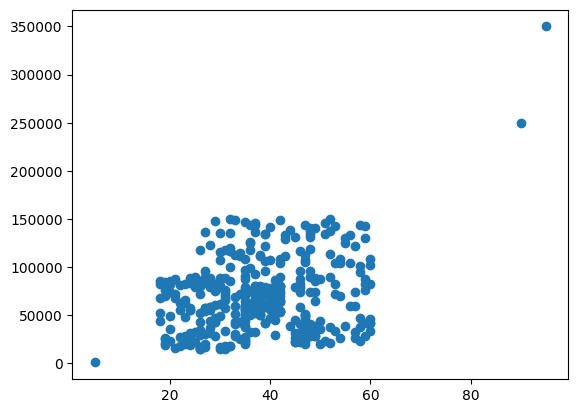

In [101]:
plt.scatter(df['Age'], df['EstimatedSalary'])

In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)

X_train.shape, X_test.shape

((282, 2), (121, 2))

In [103]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [104]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

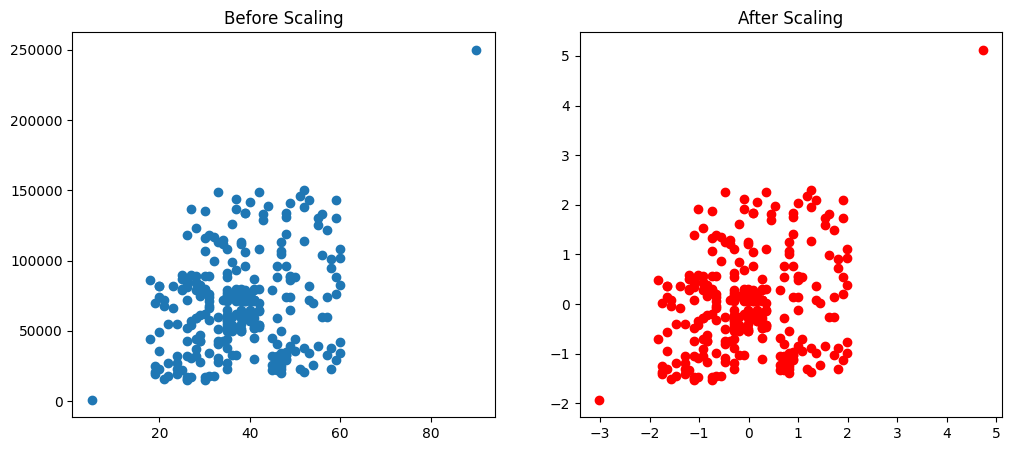

In [105]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title("After Scaling")
plt.show()

### Above code tells us that the outlier effect the dataset and after standardization to it doesnt change much so for many algorithm to function properly we need deal with outleir